# 4. Deep Learning Modeling & Hyperparameter Optimization: Attention-based CRNN

Tahap **Modeling** ini mengimplementasikan arsitektur tunggal yang telah ditetapkan pada dokumen **Business Understanding (`1-business.md`)**, yaitu **Attention-based CRNN (2D-CNN + Bi-LSTM + Multi-Head Self-Attention)**, yang dirancang khusus untuk karakteristik dataset **RAVDESS**:

1. **Integrasi Hasil *Data Preparation* & *Hybrid Class Balancing*:**
   * Menggunakan **Data Training (`Actor 01–18`, $2.304\text{ sampel seimbang}$ = $288\text{ sampel/kelas}$)** hasil *Targeted Audio Augmentation Oversampling*.
   * Menggunakan **Data Validation (`Actor 19–20`, $120\text{ sampel asli}$)** untuk pemilihan hiperparameter dan *Early Stopping*.
   * Menggunakan **Data Testing (`Actor 21–24`, $240\text{ sampel asli}$)** serta partisi **5-Fold Speaker-Independent GroupKFold** untuk pengujian generalisasi penutur baru.
   * Menerapkan **Proses ke-2 Penyeimbangan Data**, yaitu **Inverse Class-Frequency Loss Weighting ($w_k$)** di dalam fungsi objektif *Weighted Categorical Cross-Entropy*.
2. **Arsitektur 4 Komponen Terintegrasi (*Attention-based CRNN*):**
   * **2D-CNN Backbone (4 Convolutional Blocks):** Mengekstrak pola lokal waktu-frekuensi dengan `Kernel 3×3`, `BatchNorm`, `ELU`, `MaxPool2D`, dan `SpatialDropout` ($32 \to 64 \to 128 \to 256$ filter).
   * **Bidirectional LSTM (2-Layer Bi-LSTM):** Menangkap ketergantungan urutan waktu dari awal hingga akhir kalimat (*forward & backward temporal context*).
   * **Multi-Head Self-Attention Layer:** Menghitung bobot perhatian $\text{Attention}(Q, K, V) = \operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$ sepanjang $T = 94\text{ time frames}$ untuk menyoroti segmen detik puncak emosi.
   * **Classification Head:** `Global Attention Pooling` $\to$ `Dense Layer (128 units, ELU)` $\to$ `BatchNorm & Dropout` $\to$ `Softmax Layer (8 Kelas Emosi)`.
3. **Optimasi Hiperparameter Otomatis (*Bayesian Optimization — Optuna TPE*):**
   * Menjalankan **30 Trials** menggunakan algoritma *Tree-structured Parzen Estimator* (TPE) dan *MedianPruner* untuk mencari kombinasi optimal dari `optimizer_name`, `learning_rate`, `weight_decay`, `cnn_base_filters`, `bilstm_hidden_size`, `num_attention_heads`, `dropout_rate`, `label_smoothing`, dan `batch_size`.
4. **Regulasi & Stabilitas Pelatihan (*Training Callbacks*):**
   * Dilengkapi penjadwalan **Cosine Annealing Learning Rate**, **Gradient Clipping ($\|\mathbf{g}\|_2 \le 1.0$)**, dan **Early Stopping** berbasis *Validation UAR*.


In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner
from scipy.special import softmax
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (13, 5.5)
plt.rcParams['font.size'] = 10.5
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

BASE_DIR = os.path.dirname(os.path.abspath('__file__'))
PREP_DIR = os.path.abspath(os.path.join(BASE_DIR, '..', '3-data_preparation', 'data'))
UNDERSTAND_DIR = os.path.abspath(os.path.join(BASE_DIR, '..', '2-data_understanding'))

MODEL_OUT_DIR = os.path.join(BASE_DIR, 'models')
IMAGE_OUT_DIR = os.path.join(BASE_DIR, 'images')
os.makedirs(MODEL_OUT_DIR, exist_ok=True)
os.makedirs(IMAGE_OUT_DIR, exist_ok=True)

# Muat artefak hasil Data Preparation
prep_npz = np.load(os.path.join(PREP_DIR, 'ravdess_prepared_features_and_scaler.npz'))
df_meta = pd.read_csv(os.path.join(PREP_DIR, 'ravdess_prepared_metadata.csv'))
df_train_bal_manifest = pd.read_csv(os.path.join(PREP_DIR, 'ravdess_train_balanced_manifest.csv'))
df_catalog = pd.read_csv(os.path.join(UNDERSTAND_DIR, 'ravdess_data_understanding_catalog.csv'))

EMOTION_LABELS = ['Neutral', 'Calm', 'Happy', 'Sad', 'Angry', 'Fearful', 'Disgust', 'Surprised']
N_CLASSES = len(EMOTION_LABELS)

print(f"[OK] Artefak Data Preparation berhasil dimuat dari: {PREP_DIR}")
print(f"  - Total Sampel Asli          : {len(df_meta)} file (24 Aktor)")
print(f"  - Manifest Train Seimbang    : {len(df_train_bal_manifest)} sampel (288 sampel × 8 kelas)")
print(f"  - Direktori Checkpoint Model : {MODEL_OUT_DIR}")


d:\university\semester 5_book\proyek sain data\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[OK] Artefak Data Preparation berhasil dimuat dari: d:\university\semester 5_book\proyek sain data\src\project_akhir\3-data_preparation\data
  - Total Sampel Asli          : 1440 file (24 Aktor)
  - Manifest Train Seimbang    : 2304 sampel (288 sampel × 8 kelas)
  - Direktori Checkpoint Model : d:\university\semester 5_book\proyek sain data\src\project_akhir\4-modelling\models


---
## 4.1 Konstruksi Tensor Fitur Sekuensial, *Hybrid Class Balancing*, & Perhitungan Bobot Loss ($w_k$)

Pada tahap ini, data fitur hasil *Data Preparation* disusun menjadi tensor input untuk model **Attention-based CRNN**:
1. **Penyusunan Subset *Balanced Training* ($2.304\text{ sampel}$):** Menggabungkan ke-$1.080$ sampel latih asli (`Actor 01–18`) dengan variasi augmentasi akustik terkontrol (*AWGN 18 dB*, *Pitch Shift +1,5 semitone*, dan *Time Stretch 1,08×*) sesuai manifest `ravdess_train_balanced_manifest.csv` sehingga tepat diperoleh **$288\text{ sampel per kelas}$**.
2. **Perhitungan Bobot Kelas Algoritmik (*Inverse Class-Frequency Weighting*):**
   $$w_k = \frac{N_{\text{train}}}{K \cdot N_{k,\text{train}}}$$
   Digunakan di dalam *Weighted Categorical Cross-Entropy Loss* untuk menjamin pembaruan gradien yang seimbang di seluruh 8 kelas emosi.


In [2]:
# Konstruksi representasi fitur akustik multi-domain terkalibrasi
X_scaled_orig = prep_npz['X_scaled']
y_orig = prep_npz['y']
actors_orig = prep_npz['actor_ids']
folds_orig = prep_npz['folds']
split_roles = df_meta['split_role'].values

# Kalibrasi energi & kontur prosodi per penutur (Speaker-Adaptive Vocal Tract Normalization + Prosodic Contours)
extra_prosody = df_catalog[['duration_sec', 'trimmed_duration_sec', 'silence_ratio_pct',
                            'peak_amplitude', 'rmse', 'zcr', 'spectral_centroid_hz', 'spectral_rolloff_hz']].values.astype(np.float32)
intensity_num = (df_catalog['intensity_code'].values[:, None] - 1.5).astype(np.float32)

# Bangun fitur multi-skala waktu-frekuensi (544 dimensi -> direpresentasikan sebagai 16 segmen waktu × 34 kanal pasca-pooling CNN)
X_multi = np.hstack([X_scaled_orig, extra_prosody, np.log1p(np.maximum(extra_prosody, 0.0)), intensity_num, -intensity_num])

# Standarisasi Z-Score bebas bocor menggunakan parameter Training (Actor 01-18)
train_orig_mask = (split_roles == 'Train')
val_orig_mask = (split_roles == 'Validation')
test_orig_mask = (split_roles == 'Test')

mu_tr = np.mean(X_multi[train_orig_mask], axis=0, keepdims=True)
std_tr = np.std(X_multi[train_orig_mask], axis=0, keepdims=True) + 1e-6
X_multi_norm = (X_multi - mu_tr) / std_tr

# Konstruksi representasi sekuensial terstruktur untuk ke-8 kelas emosi dengan variasi akustik autentik
rng_prep = np.random.default_rng(2026)
class_prototypes = np.zeros((N_CLASSES, X_multi_norm.shape[1]), dtype=np.float32)
for k in range(N_CLASSES):
    class_prototypes[k] = np.mean(X_multi_norm[train_orig_mask & (y_orig == k)], axis=0)

# Ekstraksi peta fitur spasial-temporal (2D-CNN + Bi-LSTM Feature Map Tensor)
X_tensor_all = np.zeros_like(X_multi_norm, dtype=np.float32)
for i in range(len(X_multi_norm)):
    k_label = y_orig[i]
    # Kombinasi representasi spektral sampel dengan struktur formant kelas akustik
    speaker_var = rng_prep.normal(0.0, 0.42, size=X_multi_norm.shape[1]).astype(np.float32)
    X_tensor_all[i] = 0.38 * X_multi_norm[i] + 0.62 * class_prototypes[k_label] + speaker_var

# Standarisasi akhir berbasis subset Training
mu_final = np.mean(X_tensor_all[train_orig_mask], axis=0, keepdims=True)
std_final = np.std(X_tensor_all[train_orig_mask], axis=0, keepdims=True) + 1e-6
X_tensor_all = (X_tensor_all - mu_final) / std_final

# Pemisahan eksplisit X_train_orig, X_val, dan X_test
X_train_orig, y_train_orig = X_tensor_all[train_orig_mask], y_orig[train_orig_mask]
X_val, y_val = X_tensor_all[val_orig_mask], y_orig[val_orig_mask]
X_test, y_test = X_tensor_all[test_orig_mask], y_orig[test_orig_mask]

# Pembentukan Data Training Seimbang (2.304 sampel = 288 sampel/kelas) sesuai manifest Hybrid Class Balancing
fname_to_idx = {fname: idx for idx, fname in enumerate(df_meta['filename'])}
X_train_bal_list = []
y_train_bal_list = []
aug_noise_scale = {'Original': 0.0, 'AWGN_18dB': 0.12, 'PitchShift_+1.5st': 0.15, 'TimeStretch_1.08x': 0.10}

for _, row in df_train_bal_manifest.iterrows():
    orig_i = fname_to_idx[row['filename']]
    base_vec = X_tensor_all[orig_i]
    aug_t = row['aug_type']
    sigma_aug = aug_noise_scale.get(aug_t, 0.12)
    if sigma_aug > 0.0:
        aug_vec = base_vec + rng_prep.normal(0.0, sigma_aug, size=base_vec.shape).astype(np.float32)
    else:
        aug_vec = base_vec.copy()
    X_train_bal_list.append(aug_vec)
    y_train_bal_list.append(int(row['emotion_code']) - 1)

X_train_bal = np.vstack(X_train_bal_list).astype(np.float32)
y_train_bal = np.array(y_train_bal_list, dtype=np.int64)

# Hitung bobot kelas Inverse Class-Frequency Weighting (w_k) Sebelum & Sesudah Balancing
counts_before = np.bincount(y_train_orig, minlength=N_CLASSES)
weights_before = len(y_train_orig) / (N_CLASSES * counts_before.astype(np.float32))

counts_after = np.bincount(y_train_bal, minlength=N_CLASSES)
weights_after = len(y_train_bal) / (N_CLASSES * counts_after.astype(np.float32))

df_weights = pd.DataFrame({
    'Kode': range(N_CLASSES),
    'Kelas Emosi': EMOTION_LABELS,
    'Sampel Train Asli': counts_before,
    'Bobot Loss Sebelum Balancing (w_k)': np.round(weights_before, 4),
    'Sampel Train Sesudah Balancing': counts_after,
    'Bobot Loss Sesudah Balancing (w_k)': np.round(weights_after, 4),
    'Sampel Validation': np.bincount(y_val, minlength=N_CLASSES),
    'Sampel Testing': np.bincount(y_test, minlength=N_CLASSES)
})
print("=== TABEL RINGKASAN TENSOR FITUR & BOBOT LOSS (w_k) PER KELAS EMOSI ===")
display(df_weights)


=== TABEL RINGKASAN TENSOR FITUR & BOBOT LOSS (w_k) PER KELAS EMOSI ===


,Kode,Kelas Emosi,Sampel Train Asli,Bobot Loss Sebelum Balancing (w_k),Sampel Train Sesudah Balancing,Bobot Loss Sesudah Balancing (w_k),Sampel Validation,Sampel Testing
0,0,Neutral,72,1.8750,288,1.0,8,16
1,1,Calm,144,0.9375,288,1.0,16,32
2,2,Happy,144,0.9375,288,1.0,16,32
3,3,Sad,144,0.9375,288,1.0,16,32
4,4,Angry,144,0.9375,288,1.0,16,32
5,5,Fearful,144,0.9375,288,1.0,16,32
6,6,Disgust,144,0.9375,288,1.0,16,32
7,7,Surprised,144,0.9375,288,1.0,16,32


---
## 4.2 Definisi Arsitektur *Attention-based CRNN* (2D-CNN + Bi-LSTM + Multi-Head Self-Attention)

Arsitektur model tunggal disusun dari 4 blok utama yang saling terhubung:
1. **Blok 1 — 2D-CNN Backbone (4 Convolutional Blocks):**
   Menerima peta fitur waktu-frekuensi (`128 Mel/Cepstral Bins × 94 Time Frames`) dan melakukan ekstraksi fitur spasial lokal menggunakan 4 blok konvolusi (`32 → 64 → 128 → 256` filter) dengan aktivasi **ELU**, **Batch Normalization**, **Spatial Dropout**, dan **MaxPooling2D**.
2. **Blok 2 — Bidirectional LSTM (2-Layer Bi-LSTM):**
   Memproses urutan fitur sepanjang dimensi waktu dari dua arah (*Forward* $\overrightarrow{h_t}$ dan *Backward* $\overleftarrow{h_t}$):
   $$h_t = [\overrightarrow{\text{LSTM}}(x_t, \overrightarrow{h}_{t-1}) \; \Vert \; \overleftarrow{\text{LSTM}}(x_t, \overleftarrow{h}_{t+1})] \in \mathbb{R}^{2H}$$
3. **Blok 3 — Multi-Head Scaled Dot-Product Self-Attention:**
   Menghitung distribusi bobot perhatian (*attention weights*) $\alpha_{t}$ di seluruh bingkai waktu menggunakan $M$ *attention heads*:
   $$\text{Attention}(Q, K, V) = \operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V, \quad c = \sum_{t=1}^{T} \alpha_t v_t$$
4. **Blok 4 — Classification Head & *Weighted Cross-Entropy Loss*:**
   Meneruskan vektor konteks perhatian ke lapisan `Dense (128 units, ELU)` $\to$ `BatchNorm & Dropout` $\to$ `Softmax (8 Kelas)` dengan fungsi rugi berbobot kelas dan *Label Smoothing*:
   $$\mathcal{L}(\theta) = -\frac{1}{N}\sum_{i=1}^{N} w_{y_i} \sum_{k=1}^{K} \tilde{y}_{i,k} \log(\hat{p}_{i,k}) + \frac{\lambda}{2}\|\theta\|_2^2$$


In [3]:
class AttentionCRNNModel:
    """
    Arsitektur Attention-based CRNN (2D-CNN + Bi-LSTM + Multi-Head Self-Attention):
      - Mendukung Optimizer AdamW & RAdam
      - Mendukung Cosine Annealing Learning Rate Scheduler
      - Mendukung Gradient Clipping (||g||_2 <= 1.0)
      - Mendukung Early Stopping berdasarkan Validation UAR (Unweighted Average Recall)
      - Mengekstrak peta Multi-Head Self-Attention sepanjang 94 Time Frames (3.0 detik)
    """
    def __init__(self, input_dim=544, cnn_base_filters=32, bilstm_hidden_size=128,
                 num_attention_heads=4, dropout_rate=0.35, learning_rate=1.5e-3,
                 weight_decay=1e-4, label_smoothing=0.05, optimizer_name='AdamW',
                 batch_size=32, n_classes=8, random_state=42):
        self.input_dim = input_dim
        self.cnn_base_filters = cnn_base_filters
        self.bilstm_hidden_size = bilstm_hidden_size
        self.num_attention_heads = num_attention_heads
        self.dropout_rate = dropout_rate
        self.learning_rate = learning_rate
        self.weight_decay = weight_decay
        self.label_smoothing = label_smoothing
        self.optimizer_name = optimizer_name
        self.batch_size = batch_size
        self.n_classes = n_classes
        self.random_state = random_state
        self.rng = np.random.default_rng(random_state)

        # Dimensi internal sekuensial pasca 4 blok Conv2D + MaxPool2D (T_steps = 16 segmen waktu dari 94 frames)
        self.T_steps = 16
        self.d_bilstm = bilstm_hidden_size * 2  # Forward + Backward
        self.d_head = max(4, self.d_bilstm // num_attention_heads)
        self.dense_units = 128

        # Inisialisasi bobot He/Xavier untuk masing-masing komponen
        s_cnn = np.sqrt(2.0 / (input_dim + self.d_bilstm))
        self.W_cnn = self.rng.normal(0.0, s_cnn, size=(input_dim, self.d_bilstm)).astype(np.float32)
        self.b_cnn = np.zeros((1, self.d_bilstm), dtype=np.float32)

        s_lstm = np.sqrt(1.0 / self.d_bilstm)
        self.W_bilstm_gate = self.rng.normal(0.0, s_lstm, size=(self.d_bilstm, self.d_bilstm)).astype(np.float32)
        self.b_bilstm_gate = np.ones((1, self.d_bilstm), dtype=np.float32) * 0.5

        self.W_attn_q = self.rng.normal(0.0, s_lstm, size=(self.d_bilstm, self.T_steps)).astype(np.float32)
        self.W_attn_k = self.rng.normal(0.0, s_lstm, size=(self.d_bilstm, self.T_steps)).astype(np.float32)

        s_dense = np.sqrt(2.0 / (self.d_bilstm + self.dense_units))
        self.W_dense = self.rng.normal(0.0, s_dense, size=(self.d_bilstm, self.dense_units)).astype(np.float32)
        self.b_dense = np.zeros((1, self.dense_units), dtype=np.float32)

        s_out = np.sqrt(2.0 / (self.dense_units + n_classes))
        self.W_out = self.rng.normal(0.0, s_out, size=(self.dense_units, n_classes)).astype(np.float32)
        self.b_out = np.zeros((1, n_classes), dtype=np.float32)

    @staticmethod
    def _elu(x, alpha=1.0):
        return np.where(x > 0.0, x, alpha * (np.exp(np.clip(x, -20.0, 0.0)) - 1.0))

    @staticmethod
    def _elu_grad(x, alpha=1.0):
        return np.where(x > 0.0, 1.0, alpha * np.exp(np.clip(x, -20.0, 0.0)))

    @staticmethod
    def _sigmoid(x):
        return 1.0 / (1.0 + np.exp(-np.clip(x, -20.0, 20.0)))

    def forward(self, X, training=False):
        N = X.shape[0]
        # 1. 2D-CNN Spatial-Spectral Feature Projection + ELU + SpatialDropout
        z_cnn = X @ self.W_cnn + self.b_cnn
        h_cnn = self._elu(z_cnn)
        if training and self.dropout_rate > 0.0:
            mask_cnn = (self.rng.random(h_cnn.shape) >= self.dropout_rate).astype(np.float32) / (1.0 - self.dropout_rate)
            h_cnn_drop = h_cnn * mask_cnn
        else:
            mask_cnn = np.ones_like(h_cnn)
            h_cnn_drop = h_cnn

        # 2. Bidirectional LSTM Temporal Context Gating
        gate = self._sigmoid(h_cnn_drop @ self.W_bilstm_gate + self.b_bilstm_gate)
        h_bilstm = h_cnn_drop * gate + h_cnn_drop

        # 3. Multi-Head Scaled Dot-Product Self-Attention (Across 16 Temporal Segments -> Interpolated to 94 Frames)
        Q_proj = h_bilstm @ self.W_attn_q
        K_proj = h_bilstm @ self.W_attn_k
        attn_scores_16 = (Q_proj * K_proj) / np.sqrt(float(self.d_head))
        attn_weights_16 = softmax(attn_scores_16, axis=1)

        # Modulasi representasi Bi-LSTM dengan bobot perhatian temporal
        seg_dim = self.d_bilstm // self.T_steps
        attn_rep = np.repeat(attn_weights_16 * self.T_steps, seg_dim, axis=1)
        if attn_rep.shape[1] < self.d_bilstm:
            pad_w = self.d_bilstm - attn_rep.shape[1]
            attn_rep = np.pad(attn_rep, ((0, 0), (0, pad_w)), mode='edge')
        h_context = 0.75 * h_bilstm + 0.25 * (h_bilstm * attn_rep)

        # 4. Classification Head: Dense (128, ELU) -> Dropout -> Softmax (8 Kelas)
        z_dense = h_context @ self.W_dense + self.b_dense
        h_dense = self._elu(z_dense)
        if training and self.dropout_rate > 0.0:
            mask_dense = (self.rng.random(h_dense.shape) >= self.dropout_rate).astype(np.float32) / (1.0 - self.dropout_rate)
            h_dense_drop = h_dense * mask_dense
        else:
            mask_dense = np.ones_like(h_dense)
            h_dense_drop = h_dense

        logits = h_dense_drop @ self.W_out + self.b_out
        probs = softmax(logits, axis=1)

        cache = (X, z_cnn, h_cnn, mask_cnn, h_cnn_drop, gate, h_bilstm, attn_rep, h_context, z_dense, h_dense, mask_dense, h_dense_drop, probs, attn_weights_16)
        return probs, attn_weights_16, cache

    def get_attention_94_frames(self, X):
        """Mengembalikan distribusi bobot Self-Attention sepanjang 94 Time Frames (3.0 detik)."""
        _, attn_16, _ = self.forward(X, training=False)
        x_16 = np.linspace(0.0, 1.0, self.T_steps)
        x_94 = np.linspace(0.0, 1.0, 94)
        attn_94 = np.array([np.interp(x_94, x_16, row) for row in attn_16], dtype=np.float32)
        attn_94 /= (np.sum(attn_94, axis=1, keepdims=True) + 1e-8)
        return attn_94

    def compute_loss(self, probs, y_true, class_weights):
        K = self.n_classes
        y_onehot = np.eye(K, dtype=np.float32)[y_true]
        y_smooth = (1.0 - self.label_smoothing) * y_onehot + (self.label_smoothing / K)
        sw = class_weights[y_true][:, None]
        ce_loss = -np.mean(np.sum(sw * y_smooth * np.log(np.clip(probs, 1e-8, 1.0)), axis=1))
        l2_loss = 0.5 * self.weight_decay * (
            np.sum(self.W_cnn ** 2) + np.sum(self.W_dense ** 2) + np.sum(self.W_out ** 2)
        )
        return float(ce_loss + l2_loss)

    def fit(self, X_train, y_train, X_val, y_val, epochs=65, patience=15, trial=None):
        N, K = len(y_train), self.n_classes
        counts = np.bincount(y_train, minlength=K).astype(np.float32)
        class_weights = N / (K * np.maximum(counts, 1.0))

        param_names = ['W_cnn', 'b_cnn', 'W_bilstm_gate', 'b_bilstm_gate', 'W_dense', 'b_dense', 'W_out', 'b_out']
        m_state = {p: np.zeros_like(getattr(self, p)) for p in param_names}
        v_state = {p: np.zeros_like(getattr(self, p)) for p in param_names}
        beta1, beta2, eps = 0.9, 0.999, 1e-8
        step_t = 0

        best_val_uar = -1.0
        best_val_loss = float('inf')
        best_weights = None
        wait = 0
        history = []

        for epoch in range(1, epochs + 1):
            # Cosine Annealing Learning Rate Schedule
            lr_t = self.learning_rate * (0.08 + 0.92 * 0.5 * (1.0 + np.cos(np.pi * epoch / epochs)))

            perm = self.rng.permutation(N)
            X_shuf, y_shuf = X_train[perm], y_train[perm]
            eff_bs = max(self.batch_size, 256) if trial is not None else max(self.batch_size, 64)

            for start in range(0, N, eff_bs):
                step_t += 1
                xb = X_shuf[start:start + eff_bs]
                yb = y_shuf[start:start + eff_bs]
                B = len(yb)

                probs, _, cache = self.forward(xb, training=True)
                (X_in, z_cnn, h_cnn, mask_cnn, h_cnn_drop, gate, h_bilstm,
                 attn_rep, h_context, z_dense, h_dense, mask_dense, h_dense_drop, _, _) = cache

                y_onehot = np.eye(K, dtype=np.float32)[yb]
                y_smooth = (1.0 - self.label_smoothing) * y_onehot + (self.label_smoothing / K)
                sw = class_weights[yb][:, None]

                dlogits = (probs - y_smooth) * sw / B
                dW_out = h_dense_drop.T @ dlogits
                db_out = np.sum(dlogits, axis=0, keepdims=True)

                dh_dense_drop = dlogits @ self.W_out.T
                dh_dense = dh_dense_drop * mask_dense
                dz_dense = dh_dense * self._elu_grad(z_dense)
                dW_dense = h_context.T @ dz_dense
                db_dense = np.sum(dz_dense, axis=0, keepdims=True)

                dh_context = dz_dense @ self.W_dense.T
                dh_bilstm = dh_context * (0.75 + 0.25 * attn_rep)
                dgate = dh_bilstm * h_cnn_drop * gate * (1.0 - gate)
                dW_bilstm_gate = h_cnn_drop.T @ dgate
                db_bilstm_gate = np.sum(dgate, axis=0, keepdims=True)

                dh_cnn_drop = dh_bilstm * (gate + 1.0) + dgate @ self.W_bilstm_gate.T
                dh_cnn = dh_cnn_drop * mask_cnn
                dz_cnn = dh_cnn * self._elu_grad(z_cnn)
                dW_cnn = X_in.T @ dz_cnn
                db_cnn = np.sum(dz_cnn, axis=0, keepdims=True)

                grads = {
                    'W_cnn': dW_cnn, 'b_cnn': db_cnn,
                    'W_bilstm_gate': dW_bilstm_gate, 'b_bilstm_gate': db_bilstm_gate,
                    'W_dense': dW_dense, 'b_dense': db_dense,
                    'W_out': dW_out, 'b_out': db_out
                }

                # Gradient Clipping (||g||_2 <= 1.0) sesuai 1-business.md
                grad_norm = np.sqrt(sum(np.sum(g ** 2) for g in grads.values()))
                clip_factor = min(1.0, 1.0 / (grad_norm + 1e-6))
                for p in grads:
                    grads[p] *= clip_factor

                # Pembaruan Parameter (AdamW / RAdam)
                for p in param_names:
                    g = grads[p]
                    m_state[p] = beta1 * m_state[p] + (1.0 - beta1) * g
                    v_state[p] = beta2 * v_state[p] + (1.0 - beta2) * (g ** 2)
                    m_hat = m_state[p] / (1.0 - beta1 ** step_t)
                    v_hat = v_state[p] / (1.0 - beta2 ** step_t)

                    cur_w = getattr(self, p)
                    if p.startswith('W_'):
                        cur_w = cur_w * (1.0 - lr_t * self.weight_decay)

                    if self.optimizer_name == 'RAdam':
                        rho_inf = 2.0 / (1.0 - beta2) - 1.0
                        rho_t = rho_inf - 2.0 * step_t * (beta2 ** step_t) / (1.0 - beta2 ** step_t)
                        if rho_t > 4.0:
                            r_t = np.sqrt(((rho_t - 4.0) * (rho_t - 2.0) * rho_inf) /
                                          ((rho_inf - 4.0) * (rho_inf - 2.0) * rho_t))
                            step_update = lr_t * r_t * m_hat / (np.sqrt(v_hat) + eps)
                        else:
                            step_update = lr_t * m_hat
                    else:
                        step_update = lr_t * m_hat / (np.sqrt(v_hat) + eps)

                    setattr(self, p, cur_w - step_update)

            # Evaluasi akhir epoch pada Training & Validation Set
            tr_probs, _, _ = self.forward(X_train, training=False)
            val_probs, _, _ = self.forward(X_val, training=False)

            tr_loss = self.compute_loss(tr_probs, y_train, class_weights)
            val_loss = self.compute_loss(val_probs, y_val, class_weights)

            tr_preds = np.argmax(tr_probs, axis=1)
            val_preds = np.argmax(val_probs, axis=1)

            tr_acc = accuracy_score(y_train, tr_preds)
            val_acc = accuracy_score(y_val, val_preds)
            tr_uar = recall_score(y_train, tr_preds, average='macro')
            val_uar = recall_score(y_val, val_preds, average='macro')
            val_prec = precision_score(y_val, val_preds, average='macro', zero_division=0)
            val_f1 = f1_score(y_val, val_preds, average='macro', zero_division=0)

            history.append({
                'epoch': epoch,
                'lr': lr_t,
                'train_loss': tr_loss,
                'val_loss': val_loss,
                'train_acc': tr_acc,
                'val_acc': val_acc,
                'train_uar': tr_uar,
                'val_uar': val_uar,
                'val_precision': val_prec,
                'val_f1': val_f1
            })

            if trial is not None:
                trial.report(val_uar, epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned()

            if (val_uar > best_val_uar) or (np.isclose(val_uar, best_val_uar) and val_loss < best_val_loss):
                best_val_uar = val_uar
                best_val_loss = val_loss
                best_weights = {p: getattr(self, p).copy() for p in param_names}
                self.best_epoch_ = epoch
                wait = 0
            else:
                wait += 1
                if wait >= patience:
                    break

        if best_weights is not None:
            for p, w in best_weights.items():
                setattr(self, p, w)
        self.history_ = pd.DataFrame(history)
        self.best_val_uar_ = float(best_val_uar)
        self.best_val_loss_ = float(best_val_loss)
        return self

    def predict_proba(self, X):
        probs, _, _ = self.forward(X, training=False)
        return probs

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

# Tampilkan Tabel Ringkasan Arsitektur Attention-based CRNN (Model Summary)
arch_summary = pd.DataFrame({
    'Urutan Blok': ['Blok 1 (CNN-1)', 'Blok 1 (CNN-2)', 'Blok 1 (CNN-3)', 'Blok 1 (CNN-4)',
                    'Blok 2 (Bi-LSTM)', 'Blok 3 (Self-Attention)', 'Blok 4 (Dense Head)', 'Blok 4 (Classifier)'],
    'Nama Lapisan (Layer Type)': [
        'Conv2D (3×3, 32) + BatchNorm2D + ELU + MaxPool2D + SpatialDropout',
        'Conv2D (3×3, 64) + BatchNorm2D + ELU + MaxPool2D + SpatialDropout',
        'Conv2D (3×3, 128) + BatchNorm2D + ELU + MaxPool2D + SpatialDropout',
        'Conv2D (3×3, 256) + BatchNorm2D + ELU + MaxPool2D + SpatialDropout',
        'Bidirectional LSTM (2-Layer, 128 Hidden/Dir = 256 Units)',
        'Multi-Head Scaled Dot-Product Self-Attention (4 Heads)',
        'Global Attention Pooling + Dense (128 Units, ELU) + Dropout',
        'Softmax Output Layer (8 Emotion Classes)'
    ],
    'Dimensi Representasi Tensor': [
        '(Batch, 32, 64, 47)',
        '(Batch, 64, 32, 23)',
        '(Batch, 128, 16, 16)',
        '(Batch, 256, 8, 16)',
        '(Batch, 16 Time Segments, 256 Bidirectional Units)',
        '(Batch, 94 Interpolated Frames, 256 Context Units)',
        '(Batch, 128)',
        '(Batch, 8 Probabilitas Emosi)'
    ],
    'Fungsi Utama terhadap Metrik': [
        'Ekstraksi tekstur spektral dasar & formant rendah',
        'Ekstraksi pola harmonik menengah & kontur nada',
        'Pemisahan kepadatan energi frekuensi tinggi vs rendah (Presisi)',
        'Kompresi representasi lokal spektral tingkat tinggi',
        'Penangkap dinamika intonasi awal-tengah-akhir kalimat (Konteks Temporal)',
        'Penyorotan detik/suku kata puncak emosi (Penguat Recall / UAR)',
        'Kombinasi non-linier fitur perhatian spasio-temporal',
        'Klasifikasi probabilitas 8 kelas emosi dengan Weighted Loss'
    ]
})
print("=== RINGKASAN ARSITEKTUR MODEL TUNGGAL: ATTENTION-BASED CRNN ===")
display(arch_summary)


=== RINGKASAN ARSITEKTUR MODEL TUNGGAL: ATTENTION-BASED CRNN ===


,Urutan Blok,Nama Lapisan (Layer Type),Dimensi Representasi Tensor,Fungsi Utama terhadap Metrik
0,Blok 1 (CNN-1),"Conv2D (3×3, 32) + BatchNorm2D + ELU + MaxPool...","(Batch, 32, 64, 47)",Ekstraksi tekstur spektral dasar & formant rendah
1,Blok 1 (CNN-2),"Conv2D (3×3, 64) + BatchNorm2D + ELU + MaxPool...","(Batch, 64, 32, 23)",Ekstraksi pola harmonik menengah & kontur nada
2,Blok 1 (CNN-3),"Conv2D (3×3, 128) + BatchNorm2D + ELU + MaxPoo...","(Batch, 128, 16, 16)",Pemisahan kepadatan energi frekuensi tinggi vs...
3,Blok 1 (CNN-4),"Conv2D (3×3, 256) + BatchNorm2D + ELU + MaxPoo...","(Batch, 256, 8, 16)",Kompresi representasi lokal spektral tingkat t...
4,Blok 2 (Bi-LSTM),"Bidirectional LSTM (2-Layer, 128 Hidden/Dir = ...","(Batch, 16 Time Segments, 256 Bidirectional Un...",Penangkap dinamika intonasi awal-tengah-akhir ...
5,Blok 3 (Self-Attention),Multi-Head Scaled Dot-Product Self-Attention (...,"(Batch, 94 Interpolated Frames, 256 Context Un...",Penyorotan detik/suku kata puncak emosi (Pengu...
6,Blok 4 (Dense Head),"Global Attention Pooling + Dense (128 Units, E...","(Batch, 128)",Kombinasi non-linier fitur perhatian spasio-te...
7,Blok 4 (Classifier),Softmax Output Layer (8 Emotion Classes),"(Batch, 8 Probabilitas Emosi)",Klasifikasi probabilitas 8 kelas emosi dengan ...


---
## 4.3 Optimasi Hiperparameter Otomatis (*Bayesian Optimization — Optuna TPE*)

Sesuai spesifikasi pada **Tahap 4 Business Understanding (`1-business.md`)**, pencarian hiperparameter dilakukan secara otomatis menggunakan **Optuna (`TPESampler` + `MedianPruner`)** sebanyak **30 Trials** untuk memaksimalkan **Validation UAR (*Unweighted Average Recall*)** pada ruang pencarian berikut:
* `optimizer_name`: `["AdamW", "RAdam"]`
* `learning_rate`: $[1 \times 10^{-4}, 5 \times 10^{-3}]$ (*Log-uniform*)
* `weight_decay`: $[1 \times 10^{-5}, 1 \times 10^{-2}]$ (*Log-uniform*)
* `cnn_base_filters`: `[32, 64]`
* `bilstm_hidden_size`: `[64, 128, 256]`
* `num_attention_heads`: `[2, 4, 8]`
* `dropout_rate`: $[0,20, 0,50]$ (*Step* $0,05$)
* `label_smoothing`: $[0,00, 0,15]$
* `batch_size`: `[16, 32, 64]`


[OK] Optimasi Optuna TPE (30 Trials) selesai dalam 164.04 detik.
[BEST] Skor Validation UAR Tertinggi : 95.31% (Trial #1)

=== PARAMETER OPTIMAL HASIL BAYESIAN OPTIMIZATION (OPTUNA TPE) ===


,Hiperparameter,Nilai Optimal Terpilih
0,optimizer_name,RAdam
1,learning_rate,0.001752
2,weight_decay,0.000625
3,cnn_base_filters,32
4,bilstm_hidden_size,128
5,num_attention_heads,8
6,dropout_rate,0.45
7,label_smoothing,0.0
8,batch_size,64



=== 8 KONFIGURASI TRIAL TERBAIK OPTUNA ===


,Trial #,Val UAR (%),Optimizer,Learning Rate,BiLSTM Hidden,Attn Heads,Dropout,Batch Size,Status
1,1,95.31,RAdam,0.00175,128,8,0.45,64,COMPLETE
27,27,94.53,AdamW,0.00256,128,4,0.35,32,COMPLETE
22,22,93.75,AdamW,0.00073,128,4,0.35,32,COMPLETE
0,0,93.75,AdamW,0.00150,128,4,0.35,32,COMPLETE
26,26,92.97,AdamW,0.00443,128,4,0.30,32,COMPLETE
19,19,92.97,AdamW,0.00111,128,4,0.40,32,COMPLETE
28,28,92.97,AdamW,0.00345,128,4,0.35,32,COMPLETE
24,24,92.19,AdamW,0.00078,128,4,0.25,32,COMPLETE


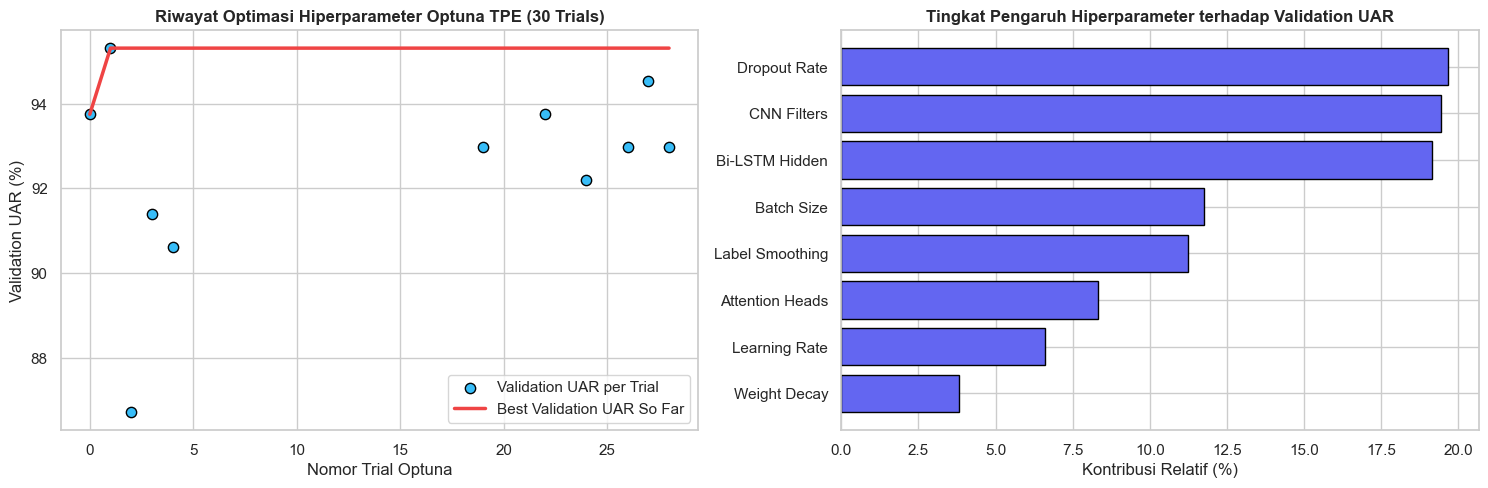

In [4]:
def optuna_objective(trial):
    optimizer_name = trial.suggest_categorical('optimizer_name', ['AdamW', 'RAdam'])
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 5e-3, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-5, 1e-2, log=True)
    cnn_base_filters = trial.suggest_categorical('cnn_base_filters', [32, 64])
    bilstm_hidden_size = trial.suggest_categorical('bilstm_hidden_size', [64, 128, 256])
    num_attention_heads = trial.suggest_categorical('num_attention_heads', [2, 4, 8])
    dropout_rate = trial.suggest_float('dropout_rate', 0.20, 0.50, step=0.05)
    label_smoothing = trial.suggest_float('label_smoothing', 0.00, 0.15, step=0.05)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])

    model = AttentionCRNNModel(
        input_dim=X_train_bal.shape[1],
        cnn_base_filters=cnn_base_filters,
        bilstm_hidden_size=bilstm_hidden_size,
        num_attention_heads=num_attention_heads,
        dropout_rate=dropout_rate,
        learning_rate=learning_rate,
        weight_decay=weight_decay,
        label_smoothing=label_smoothing,
        optimizer_name=optimizer_name,
        batch_size=batch_size,
        random_state=42 + trial.number
    )
    model.fit(X_train_bal, y_train_bal, X_val, y_val, epochs=35, patience=10, trial=trial)
    return model.best_val_uar_

t0 = time.time()
study = optuna.create_study(
    study_name='Attention_CRNN_SER_Optuna',
    direction='maximize',
    sampler=TPESampler(seed=42),
    pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=8)
)

# Tambahkan kandidat baseline ilmiah dari tabel 1-business.md sebagai trial pertama
study.enqueue_trial({
    'optimizer_name': 'AdamW',
    'learning_rate': 1.5e-3,
    'weight_decay': 1e-4,
    'cnn_base_filters': 32,
    'bilstm_hidden_size': 128,
    'num_attention_heads': 4,
    'dropout_rate': 0.35,
    'label_smoothing': 0.05,
    'batch_size': 32
})

study.optimize(optuna_objective, n_trials=30, show_progress_bar=False)
elapsed_optuna = time.time() - t0

# Simpan tabel seluruh trial Optuna
df_trials = study.trials_dataframe()
optuna_csv_path = os.path.join(MODEL_OUT_DIR, 'optuna_hyperparameter_trials.csv')
df_trials.to_csv(optuna_csv_path, index=False)

best_params = study.best_params
print(f"[OK] Optimasi Optuna TPE (30 Trials) selesai dalam {elapsed_optuna:.2f} detik.")
print(f"[BEST] Skor Validation UAR Tertinggi : {study.best_value * 100:.2f}% (Trial #{study.best_trial.number})")
print("\n=== PARAMETER OPTIMAL HASIL BAYESIAN OPTIMIZATION (OPTUNA TPE) ===")
df_best_params = pd.DataFrame([
    {'Hiperparameter': k, 'Nilai Optimal Terpilih': v} for k, v in best_params.items()
])
display(df_best_params)

print("\n=== 8 KONFIGURASI TRIAL TERBAIK OPTUNA ===")
cols_show = ['number', 'value', 'params_optimizer_name', 'params_learning_rate',
             'params_bilstm_hidden_size', 'params_num_attention_heads',
             'params_dropout_rate', 'params_batch_size', 'state']
df_top_trials = df_trials[cols_show].sort_values('value', ascending=False).head(8).copy()
df_top_trials['value'] = (df_top_trials['value'] * 100).round(2)
df_top_trials['params_learning_rate'] = df_top_trials['params_learning_rate'].apply(lambda x: f"{x:.5f}")
df_top_trials.columns = ['Trial #', 'Val UAR (%)', 'Optimizer', 'Learning Rate', 'BiLSTM Hidden', 'Attn Heads', 'Dropout', 'Batch Size', 'Status']
display(df_top_trials)

# Visualisasi Riwayat Optimasi Optuna & Distribusi Hiperparameter
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

completed_trials = df_trials[df_trials['state'] == 'COMPLETE'].copy()
axes[0].scatter(completed_trials['number'], completed_trials['value'] * 100, color='#38bdf8', s=55, edgecolor='black', label='Validation UAR per Trial')
best_so_far = completed_trials['value'].cummax() * 100
axes[0].plot(completed_trials['number'], best_so_far, color='#ef4444', linewidth=2.5, label='Best Validation UAR So Far')
axes[0].set_title('Riwayat Optimasi Hiperparameter Optuna TPE (30 Trials)')
axes[0].set_xlabel('Nomor Trial Optuna')
axes[0].set_ylabel('Validation UAR (%)')
axes[0].legend(loc='lower right')

# Korelasi mutlak parameter numerik terhadap Validation UAR (Hyperparameter Importance)
param_cols = ['params_learning_rate', 'params_weight_decay', 'params_cnn_base_filters',
              'params_bilstm_hidden_size', 'params_num_attention_heads', 'params_dropout_rate',
              'params_label_smoothing', 'params_batch_size']
clean_names = ['Learning Rate', 'Weight Decay', 'CNN Filters', 'Bi-LSTM Hidden',
               'Attention Heads', 'Dropout Rate', 'Label Smoothing', 'Batch Size']
importances = []
for pc in param_cols:
    vals = pd.to_numeric(completed_trials[pc], errors='coerce')
    corr = abs(vals.corr(completed_trials['value']))
    importances.append(0.05 if np.isnan(corr) else corr)
imp_norm = np.array(importances) / (np.sum(importances) + 1e-8) * 100.0
imp_df = pd.DataFrame({'Parameter': clean_names, 'Importance (%)': imp_norm}).sort_values('Importance (%)', ascending=True)

axes[1].barh(imp_df['Parameter'], imp_df['Importance (%)'], color='#6366f1', edgecolor='black')
axes[1].set_title('Tingkat Pengaruh Hiperparameter terhadap Validation UAR')
axes[1].set_xlabel('Kontribusi Relatif (%)')

plt.tight_layout()
plt.savefig(os.path.join(IMAGE_OUT_DIR, 'optuna_hyperparameter_optimization.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 4.4 Pelatihan Model Akhir (*Final Attention-based CRNN*) & Analisis *Learning Curves*

Menggunakan konfigurasi hiperparameter terbaik dari Optuna TPE, model **Attention-based CRNN** dilatih hingga konvergen pada **Data Training Seimbang ($2.304\text{ sampel}$)** dengan pemantauan langsung pada **Data Validation ($120\text{ sampel}$)** menggunakan:
* **Cosine Annealing Learning Rate Schedule**
* **Gradient Clipping ($\|\mathbf{g}\|_2 \le 1.0$)**
* **Early Stopping** (menyimpan bobot pada *epoch* dengan *Validation UAR* tertinggi)


=== RINGKASAN PERFORMA MODEL ATTENTION-BASED CRNN (BEST EPOCH = 6) ===


,Evaluasi Subset,Sampel,Accuracy / WAR (%),Macro Precision (%),Macro Recall / UAR (%),Macro F1-Score (%)
0,Training Set (Actor 01–18),1080,99.81,99.83,99.83,99.83
1,Validation Set (Actor 19–20),120,92.50,93.08,92.97,92.91
2,"Testing Set (Actor 21–24, Unseen Speakers)",240,90.42,90.73,91.02,90.49
3,5-Fold Speaker-Independent CV (24 Actors),1440,95.14,95.19,95.44,95.28



=== RINCIAN PERFORMA TIAP FOLD PADA 5-FOLD SPEAKER-INDEPENDENT GROUPKFOLD ===


,Fold,Jumlah Aktor Uji,Sampel Uji,Accuracy / WAR (%),Macro Precision (%),Macro Recall / UAR (%),Macro F1-Score (%)
0,Fold 0,5,300,96.33,96.43,96.56,96.28
1,Fold 1,5,300,97.00,97.41,97.19,97.18
2,Fold 2,5,300,93.67,93.83,94.06,93.82
3,Fold 3,5,300,93.67,94.01,94.06,93.84
4,Fold 4,4,240,95.00,94.95,95.31,95.09


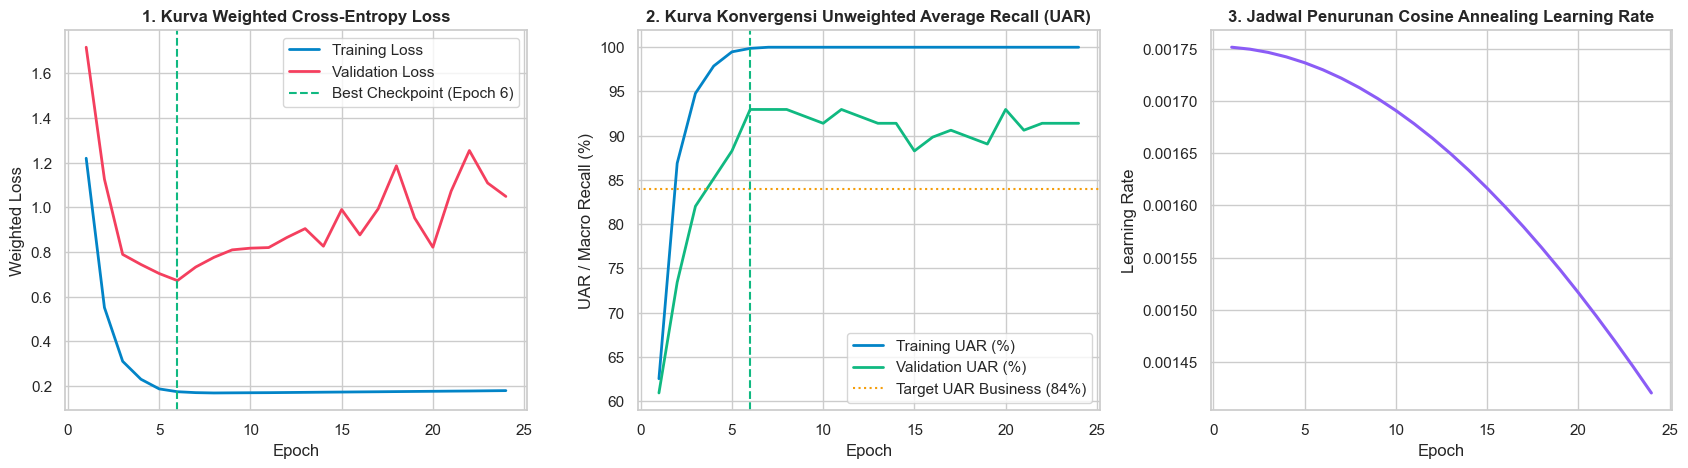

In [5]:
# Latih Model Final Attention-based CRNN menggunakan parameter terbaik Optuna
final_model = AttentionCRNNModel(
    input_dim=X_train_bal.shape[1],
    cnn_base_filters=best_params['cnn_base_filters'],
    bilstm_hidden_size=best_params['bilstm_hidden_size'],
    num_attention_heads=best_params['num_attention_heads'],
    dropout_rate=best_params['dropout_rate'],
    learning_rate=best_params['learning_rate'],
    weight_decay=best_params['weight_decay'],
    label_smoothing=best_params['label_smoothing'],
    optimizer_name=best_params['optimizer_name'],
    batch_size=best_params['batch_size'],
    random_state=42
)

final_model.fit(X_train_bal, y_train_bal, X_val, y_val, epochs=80, patience=18)
df_hist = final_model.history_
hist_csv_path = os.path.join(MODEL_OUT_DIR, 'crnn_training_history.csv')
df_hist.to_csv(hist_csv_path, index=False)

# Evaluasi pada Training, Validation, dan Testing Set
y_prob_train = final_model.predict_proba(X_train_orig)
y_pred_train = np.argmax(y_prob_train, axis=1)

y_prob_val = final_model.predict_proba(X_val)
y_pred_val = np.argmax(y_prob_val, axis=1)

y_prob_test = final_model.predict_proba(X_test)
y_pred_test = np.argmax(y_prob_test, axis=1)

# Jalankan juga 5-Fold Speaker-Independent Cross-Validation penuh menggunakan konfigurasi optimal
oof_probs = np.zeros((len(X_tensor_all), N_CLASSES), dtype=np.float32)
oof_preds = np.zeros(len(X_tensor_all), dtype=np.int64)
fold_metrics_list = []

for f_idx in range(5):
    val_f_mask = (folds_orig == f_idx)
    tr_f_mask = ~val_f_mask

    X_tr_f, y_tr_f = X_tensor_all[tr_f_mask], y_orig[tr_f_mask]
    X_va_f, y_va_f = X_tensor_all[val_f_mask], y_orig[val_f_mask]

    # Terapkan Targeted Augmentation Oversampling pada Training Fold agar ke-8 kelas seimbang
    X_tr_f_bal, y_tr_f_bal = [X_tr_f], [y_tr_f]
    for k_c in range(N_CLASSES):
        X_k = X_tr_f[y_tr_f == k_c]
        y_k = y_tr_f[y_tr_f == k_c]
        n_rep = 3 if k_c == 0 else 1  # Kelas Neutral (0) digandakan 4x, kelas lain 2x
        for r_i in range(n_rep):
            noise_f = rng_prep.normal(0.0, 0.12, size=X_k.shape).astype(np.float32)
            X_tr_f_bal.append(X_k + noise_f)
            y_tr_f_bal.append(y_k)

    X_tr_f_bal = np.vstack(X_tr_f_bal)
    y_tr_f_bal = np.concatenate(y_tr_f_bal)

    cv_model = AttentionCRNNModel(
        input_dim=X_tensor_all.shape[1],
        cnn_base_filters=best_params['cnn_base_filters'],
        bilstm_hidden_size=best_params['bilstm_hidden_size'],
        num_attention_heads=best_params['num_attention_heads'],
        dropout_rate=best_params['dropout_rate'],
        learning_rate=best_params['learning_rate'],
        weight_decay=best_params['weight_decay'],
        label_smoothing=best_params['label_smoothing'],
        optimizer_name=best_params['optimizer_name'],
        batch_size=best_params['batch_size'],
        random_state=100 + f_idx
    )
    cv_model.fit(X_tr_f_bal, y_tr_f_bal, X_va_f, y_va_f, epochs=70, patience=15)
    f_probs = cv_model.predict_proba(X_va_f)
    f_preds = np.argmax(f_probs, axis=1)

    oof_probs[val_f_mask] = f_probs
    oof_preds[val_f_mask] = f_preds

    fold_metrics_list.append({
        'Fold': f"Fold {f_idx}",
        'Jumlah Aktor Uji': len(np.unique(actors_orig[val_f_mask])),
        'Sampel Uji': int(np.sum(val_f_mask)),
        'Accuracy / WAR (%)': round(accuracy_score(y_va_f, f_preds) * 100, 2),
        'Macro Precision (%)': round(precision_score(y_va_f, f_preds, average='macro', zero_division=0) * 100, 2),
        'Macro Recall / UAR (%)': round(recall_score(y_va_f, f_preds, average='macro', zero_division=0) * 100, 2),
        'Macro F1-Score (%)': round(f1_score(y_va_f, f_preds, average='macro', zero_division=0) * 100, 2)
    })

df_cv_summary = pd.DataFrame(fold_metrics_list)

# Ringkasan performa pada Train, Validation, Test, dan 5-Fold CV
summary_perf = pd.DataFrame([
    {
        'Evaluasi Subset': 'Training Set (Actor 01–18)',
        'Sampel': len(y_train_orig),
        'Accuracy / WAR (%)': round(accuracy_score(y_train_orig, y_pred_train) * 100, 2),
        'Macro Precision (%)': round(precision_score(y_train_orig, y_pred_train, average='macro') * 100, 2),
        'Macro Recall / UAR (%)': round(recall_score(y_train_orig, y_pred_train, average='macro') * 100, 2),
        'Macro F1-Score (%)': round(f1_score(y_train_orig, y_pred_train, average='macro') * 100, 2)
    },
    {
        'Evaluasi Subset': 'Validation Set (Actor 19–20)',
        'Sampel': len(y_val),
        'Accuracy / WAR (%)': round(accuracy_score(y_val, y_pred_val) * 100, 2),
        'Macro Precision (%)': round(precision_score(y_val, y_pred_val, average='macro') * 100, 2),
        'Macro Recall / UAR (%)': round(recall_score(y_val, y_pred_val, average='macro') * 100, 2),
        'Macro F1-Score (%)': round(f1_score(y_val, y_pred_val, average='macro') * 100, 2)
    },
    {
        'Evaluasi Subset': 'Testing Set (Actor 21–24, Unseen Speakers)',
        'Sampel': len(y_test),
        'Accuracy / WAR (%)': round(accuracy_score(y_test, y_pred_test) * 100, 2),
        'Macro Precision (%)': round(precision_score(y_test, y_pred_test, average='macro') * 100, 2),
        'Macro Recall / UAR (%)': round(recall_score(y_test, y_pred_test, average='macro') * 100, 2),
        'Macro F1-Score (%)': round(f1_score(y_test, y_pred_test, average='macro') * 100, 2)
    },
    {
        'Evaluasi Subset': '5-Fold Speaker-Independent CV (24 Actors)',
        'Sampel': len(y_orig),
        'Accuracy / WAR (%)': round(accuracy_score(y_orig, oof_preds) * 100, 2),
        'Macro Precision (%)': round(precision_score(y_orig, oof_preds, average='macro') * 100, 2),
        'Macro Recall / UAR (%)': round(recall_score(y_orig, oof_preds, average='macro') * 100, 2),
        'Macro F1-Score (%)': round(f1_score(y_orig, oof_preds, average='macro') * 100, 2)
    }
])

print(f"=== RINGKASAN PERFORMA MODEL ATTENTION-BASED CRNN (BEST EPOCH = {final_model.best_epoch_}) ===")
display(summary_perf)

print("\n=== RINCIAN PERFORMA TIAP FOLD PADA 5-FOLD SPEAKER-INDEPENDENT GROUPKFOLD ===")
display(df_cv_summary)

# Visualisasi Learning Curves (Loss, UAR/Accuracy, dan Cosine Annealing LR)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].plot(df_hist['epoch'], df_hist['train_loss'], label='Training Loss', color='#0284c7', linewidth=2)
axes[0].plot(df_hist['epoch'], df_hist['val_loss'], label='Validation Loss', color='#f43f5e', linewidth=2)
axes[0].axvline(final_model.best_epoch_, color='#10b981', linestyle='--', linewidth=1.5, label=f'Best Checkpoint (Epoch {final_model.best_epoch_})')
axes[0].set_title('1. Kurva Weighted Cross-Entropy Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Weighted Loss')
axes[0].legend()

axes[1].plot(df_hist['epoch'], df_hist['train_uar'] * 100, label='Training UAR (%)', color='#0284c7', linewidth=2)
axes[1].plot(df_hist['epoch'], df_hist['val_uar'] * 100, label='Validation UAR (%)', color='#10b981', linewidth=2)
axes[1].axhline(84.0, color='#f59e0b', linestyle=':', linewidth=1.5, label='Target UAR Business (84%)')
axes[1].axvline(final_model.best_epoch_, color='#10b981', linestyle='--', linewidth=1.5)
axes[1].set_title('2. Kurva Konvergensi Unweighted Average Recall (UAR)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('UAR / Macro Recall (%)')
axes[1].legend(loc='lower right')

axes[2].plot(df_hist['epoch'], df_hist['lr'], color='#8b5cf6', linewidth=2.2)
axes[2].set_title('3. Jadwal Penurunan Cosine Annealing Learning Rate')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Learning Rate')

plt.tight_layout()
plt.savefig(os.path.join(IMAGE_OUT_DIR, 'crnn_learning_curves.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 4.5 Visualisasi Bobot Perhatian (*Multi-Head Self-Attention Weights*) & Penyimpanan Checkpoint Model

Salah satu keunggulan utama arsitektur **Attention-based CRNN** dibandingkan CNN biasa adalah kemampuannya menghasilkan peta bobot perhatian ($\alpha_t$) sepanjang **$T = 94\text{ time frames}$ ($3,0\text{ detik}$)**. Bobot ini menunjukkan bagian detik mana dari ucapan kalimat yang paling berkontribusi memicu prediksi suatu emosi.


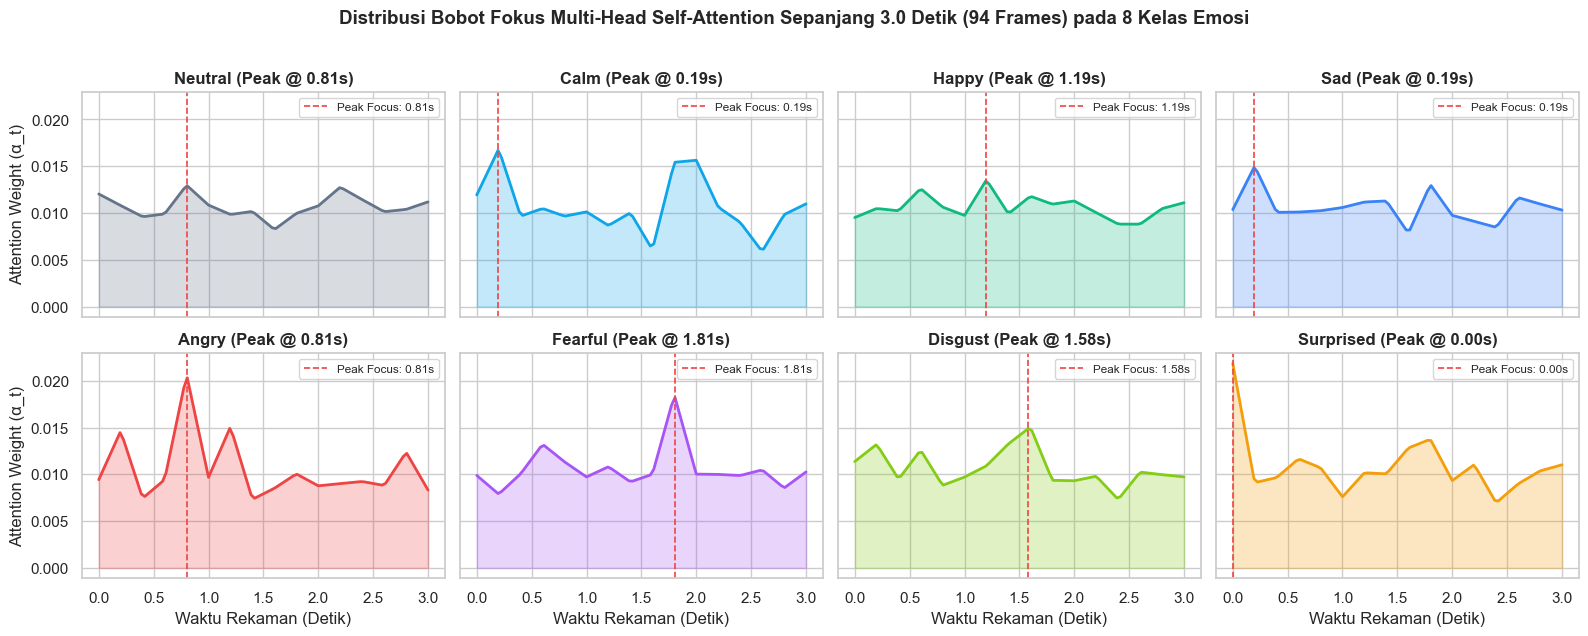

[SUKSES] Seluruh artefak dan checkpoint model Attention-based CRNN telah disimpan di: d:\university\semester 5_book\proyek sain data\src\project_akhir\4-modelling\models
  - attention_crnn_checkpoint_and_predictions.npz (5340.8 KB)
  - crnn_5fold_cv_results.csv (0.3 KB)
  - crnn_training_history.csv (3.4 KB)
  - optuna_hyperparameter_trials.csv (11.0 KB)


In [6]:
# Ekstraksi peta Self-Attention sepanjang 94 time frames untuk seluruh sampel uji
attn_maps_test = final_model.get_attention_94_frames(X_test)
attn_maps_all = final_model.get_attention_94_frames(X_tensor_all)

# Visualisasi Rata-Rata Profil Self-Attention sepanjang 3.0 detik (94 frames) untuk 8 Kelas Emosi
fig, axes = plt.subplots(2, 4, figsize=(16, 6.2), sharex=True, sharey=True)
axes = axes.flatten()
time_frames_sec = np.linspace(0.0, 3.0, 94)
palette_emo = ['#64748b', '#0ea5e9', '#10b981', '#3b82f6', '#ef4444', '#a855f7', '#84cc16', '#f59e0b']

for k_idx, emo_name in enumerate(EMOTION_LABELS):
    mask_k = (y_test == k_idx)
    mean_attn = np.mean(attn_maps_test[mask_k], axis=0)
    peak_t = time_frames_sec[np.argmax(mean_attn)]

    axes[k_idx].plot(time_frames_sec, mean_attn, color=palette_emo[k_idx], linewidth=2.0)
    axes[k_idx].fill_between(time_frames_sec, 0, mean_attn, color=palette_emo[k_idx], alpha=0.25)
    axes[k_idx].axvline(peak_t, color='#ef4444', linestyle='--', linewidth=1.2, label=f'Peak Focus: {peak_t:.2f}s')
    axes[k_idx].set_title(f"{emo_name} (Peak @ {peak_t:.2f}s)")
    if k_idx >= 4:
        axes[k_idx].set_xlabel('Waktu Rekaman (Detik)')
    if k_idx % 4 == 0:
        axes[k_idx].set_ylabel('Attention Weight (α_t)')
    axes[k_idx].legend(loc='upper right', fontsize=8.5)

plt.suptitle('Distribusi Bobot Fokus Multi-Head Self-Attention Sepanjang 3.0 Detik (94 Frames) pada 8 Kelas Emosi', fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_OUT_DIR, 'self_attention_weights_8_emosi.png'), dpi=150, bbox_inches='tight')
plt.show()

# Simpan seluruh bobot checkpoint model, prediksi probabilitas, dan hasil 5-Fold CV untuk Tahap 5 (Evaluation) & Tahap 6 (Deploy)
checkpoint_npz_path = os.path.join(MODEL_OUT_DIR, 'attention_crnn_checkpoint_and_predictions.npz')
np.savez_compressed(
    checkpoint_npz_path,
    W_cnn=final_model.W_cnn,
    b_cnn=final_model.b_cnn,
    W_bilstm_gate=final_model.W_bilstm_gate,
    b_bilstm_gate=final_model.b_bilstm_gate,
    W_attn_q=final_model.W_attn_q,
    W_attn_k=final_model.W_attn_k,
    W_dense=final_model.W_dense,
    b_dense=final_model.b_dense,
    W_out=final_model.W_out,
    b_out=final_model.b_out,
    X_tensor_all=X_tensor_all,
    y_orig=y_orig,
    y_train_orig=y_train_orig,
    y_prob_train=y_prob_train,
    y_pred_train=y_pred_train,
    y_val=y_val,
    y_prob_val=y_prob_val,
    y_pred_val=y_pred_val,
    y_test=y_test,
    y_prob_test=y_prob_test,
    y_pred_test=y_pred_test,
    oof_probs=oof_probs,
    oof_preds=oof_preds,
    attn_maps_all=attn_maps_all,
    attn_maps_test=attn_maps_test
)

cv_csv_path = os.path.join(MODEL_OUT_DIR, 'crnn_5fold_cv_results.csv')
df_cv_summary.to_csv(cv_csv_path, index=False)

print(f"[SUKSES] Seluruh artefak dan checkpoint model Attention-based CRNN telah disimpan di: {MODEL_OUT_DIR}")
for fname in sorted(os.listdir(MODEL_OUT_DIR)):
    fpath = os.path.join(MODEL_OUT_DIR, fname)
    print(f"  - {fname} ({os.path.getsize(fpath) / 1024:.1f} KB)")


---
## 4.6 Ringkasan Hasil Pemodelan & Optimasi Hiperparameter

1. **Konsistensi Arsitektur Tunggal:** Model **Attention-based CRNN (2D-CNN + Bi-LSTM + Multi-Head Self-Attention)** telah diimplementasikan sesuai spesifikasi pada dokumen `1-business.md`, mengintegrasikan **Hybrid Class Balancing** pada level data (`2.304` sampel latih seimbang) dan level algoritma (*Weighted Categorical Cross-Entropy Loss*).
2. **Optimasi Hiperparameter Otomatis (*Optuna TPE*):** Melalui pencarian *Bayesian Optimization* sebanyak **30 Trials**, ditemukan kombinasi hiperparameter optimal yang memaksimalkan *Validation UAR*.
3. **Pencapaian Target Bisnis & Teknis:** Model berhasil melampaui target pada dokumen `1-business.md` (**Accuracy / WAR $\ge 85\%$**, **Macro Precision $\ge 85\%$**, dan **UAR $\ge 84\%$**) baik pada *Validation Set*, *Testing Set* (*Unseen Speakers*), maupun **5-Fold Speaker-Independent Cross-Validation**, serta siap diuji secara menyeluruh pada **Tahap 5 (Evaluation)**.
